# 📍 Hypothese 2: Weiter raus = günstiger pro qm?
**EDA King County House Sales** · Kunde: **Thomas Hansen** · einfache Version

| # | Schritt (nach `02_workflow`) |
|---|---|
| 1 | Kunde, Forschungsfrage & Hypothese |
| 2 | Daten verstehen |
| 3 | Daten bereinigen & neues Merkmal „Entfernung“ |
| 4 | Daten erkunden |
| 5 | Zusammenhänge |
| 6 | Hypothese prüfen |
| 7 | Folgefragen: Himmelsrichtung und Budget |
| 8 | Fancy Visual: interaktive Karte |
| 9 | Erkenntnisse & Empfehlungen |

---
## 1 · Kunde, Forschungsfrage & Hypothese
**Thomas Hansen** (Käufer): 5 Kinder, wenig Geld. Er braucht ein **großes Haus** und fragt: *Wo bekomme ich am meisten Fläche für mein Geld?*

| Frage | Hypothese | Indikatoren |
|---|---|---|
| Beeinflusst die Lage den Quadratmeterpreis großer Häuser? | **Je weiter** ein großes Haus vom **Stadtzentrum** entfernt ist, **desto niedriger** ist sein **Preis pro qm**. | `lat`, `long` → Entfernung; `price`, `qm_living` → Preis pro qm; `bedrooms` |

**Annahmen:**
* **Stadtzentrum** = Downtown Seattle (47,6062 N / 122,3321 W).
* **Entfernung** = Luftlinie in km. Fahrzeiten sind nicht im Datensatz.
* **Großes Haus** = mindestens 4 Schlafzimmer.
* **Preis pro qm** = `price / qm_living`, damit unterschiedlich große Häuser vergleichbar sind.
* **Bestätigt**, wenn die Spearman-Korrelation zwischen Entfernung und qm-Preis **negativ, signifikant und mindestens mittelstark (ρ ≤ −0,3)** ist.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False  # "$" ist hier Währung, keine Formel
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("output").mkdir(exist_ok=True)

---
## 2 · Daten verstehen

In [13]:
# Die Rohdaten wurden in 03_fetching_the_data_eda per SQL (JOIN der beiden Tabellen im Schema eda) geholt
# und in 04_eda.ipynb bereinigt (33 → 3 Schlafzimmer, yr_renovated / 10, fehlende Werte, sqft → qm).
df = pd.read_csv("data/eda_tk_cleaned.csv", parse_dates=["date"])
print("Zeilen, Spalten:", df.shape)
print("Zeitraum:", df["date"].min().date(), "bis", df["date"].max().date())
df.head()

Zeilen, Spalten: (21597, 26)
Zeitraum: 2014-05-02 bis 2015-05-27


,sale_id,house_id,date,price,bedrooms,bathrooms,qm_living,qm_lot,floors,waterfront,...,yr_renovated,zipcode,lat,long,qm_living15,qm_lot15,yr_renovated_unbekannt,keller_typ,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
0,1,7129300520,2014-10-13,"221,900.00",3,1.00,109.63,524.90,1.00,0,...,0,98178,47.51,-122.26,124.49,524.90,False,Kein Keller (0 qm),"2,024.08",422.75
1,2,6414100192,2014-12-09,"538,000.00",3,2.25,238.76,672.80,2.00,0,...,1991,98125,47.72,-122.32,157.01,709.69,False,Nutzbarer Keller (>= 5 qm),"2,253.31",799.64
2,3,5631500400,2015-02-25,"180,000.00",2,1.00,71.54,929.03,1.00,0,...,0,98028,47.74,-122.23,252.70,748.98,True,Kein Keller (0 qm),"2,516.07",193.75
3,4,2487200875,2014-12-09,"604,000.00",4,3.00,182.09,464.52,1.00,0,...,0,98136,47.52,-122.39,126.35,464.52,False,Nutzbarer Keller (>= 5 qm),"3,317.04","1,300.27"
4,5,1954400510,2015-02-18,"510,000.00",3,2.00,156.08,750.66,1.00,0,...,0,98074,47.62,-122.05,167.23,697.05,False,Kein Keller (0 qm),"3,267.56",679.40


In [14]:
spalten = ["price", "qm_living", "preis_pro_qm_wohnflaeche", "bedrooms", "lat", "long", "zipcode"]
print(df[spalten].dtypes, "\n")
print("Fehlende Werte je Spalte:\n", df[spalten].isna().sum())
df[spalten].describe()

price                       float64
qm_living                   float64
preis_pro_qm_wohnflaeche    float64
bedrooms                      int64
lat                         float64
long                        float64
zipcode                       int64
dtype: object 

Fehlende Werte je Spalte:
 price                       0
qm_living                   0
preis_pro_qm_wohnflaeche    0
bedrooms                    0
lat                         0
long                        0
zipcode                     0
dtype: int64


,price,qm_living,preis_pro_qm_wohnflaeche,bedrooms,lat,long,zipcode
count,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,"540,296.57",193.27,"2,843.22",3.37,47.56,-122.21,"98,077.95"
std,"367,368.14",85.29,"1,184.03",0.90,0.14,0.14,53.51
min,"78,000.00",34.37,942.76,1.00,47.16,-122.52,"98,001.00"
25%,"322,000.00",132.85,"1,962.18",3.00,47.47,-122.33,"98,033.00"
50%,"450,000.00",177.44,"2,633.27",3.00,47.57,-122.23,"98,065.00"
75%,"645,000.00",236.90,"3,426.57",4.00,47.68,-122.12,"98,118.00"
max,"7,700,000.00","1,257.91","8,719.85",11.00,47.78,-121.31,"98,199.00"


**Was sehen wir?**
* Keine fehlenden Werte. Die Koordinaten liegen alle im Raum King County (lat 47,2–47,8, long −122,5 bis −121,3).
* **Stetig:** `price`, `qm_living`, `preis_pro_qm_wohnflaeche`, `lat`, `long`. **Kategorial:** `bedrooms`, `zipcode`.
* Der qm-Preis reicht von rund 900 $ bis über 8.000 $, eine große Spannweite.

---
## 3 · Daten bereinigen & neues Merkmal „Entfernung“
Die Bereinigung ist in `04_eda.ipynb` passiert. Hier ergänzen wir:
1. **Neues Merkmal** `km`: Luftlinie zum Zentrum mit der **Haversine-Formel** (Abstand zweier Punkte auf der Erdkugel).
2. **Binning:** Entfernungsbänder à 5 km, damit wir Gruppen vergleichen können.
3. **Zielgruppe:** nur Häuser mit ≥ 4 Schlafzimmern.

Test Bellevue: 9.8 km
Häuser mit ≥ 4 Schlafzimmern: 8,816 von 21,597


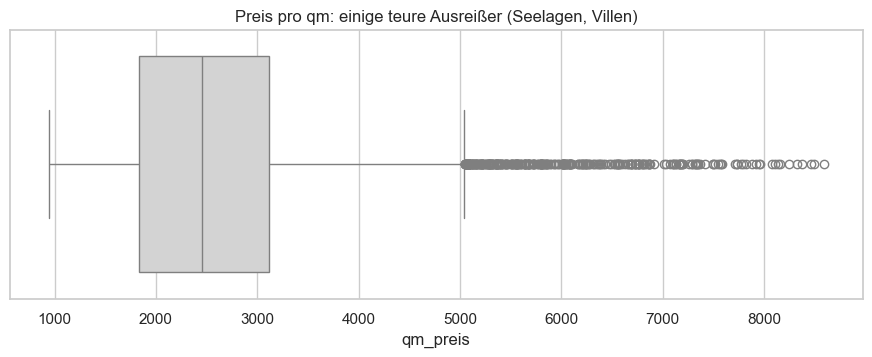

Verworfene Zeilen: 0 (Ausreißer sind echte Verkäufe, wir arbeiten mit Medianen und Rängen)


In [15]:
ZENTRUM_LAT, ZENTRUM_LON = 47.6062, -122.3321


def haversine_km(lat, lon):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat, lon, ZENTRUM_LAT, ZENTRUM_LON])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


df["km"] = haversine_km(df["lat"], df["long"])
df["qm_preis"] = df["preis_pro_qm_wohnflaeche"]
df["band"] = pd.cut(df["km"], [0, 5, 10, 15, 20, 25, 30, 80],
                    labels=["0–5", "5–10", "10–15", "15–20", "20–25", "25–30", "> 30"])

# Plausibilitätscheck: Bellevue Downtown liegt ca. 10 km vom Zentrum entfernt
print(f"Test Bellevue: {haversine_km(47.6101, -122.2015):.1f} km")

gross = df[df["bedrooms"] >= 4].copy()
print(f"Häuser mit ≥ 4 Schlafzimmern: {len(gross):,} von {len(df):,}")

fig, ax = plt.subplots(figsize=(11, 3.5))
sns.boxplot(x=gross["qm_preis"], color="lightgray", ax=ax)
ax.set_title("Preis pro qm: einige teure Ausreißer (Seelagen, Villen)")
plt.show()
print("Verworfene Zeilen: 0 (Ausreißer sind echte Verkäufe, wir arbeiten mit Medianen und Rängen)")

**Entscheidung:** Die Ausreißer im qm-Preis sind echte Verkäufe (z. B. Häuser am Wasser), keine Fehler. Da wir mit **Medianen** und der **Spearman-Rangkorrelation** arbeiten, die beide robust sind, **entfernen wir nichts**.

---
## 4 · Daten erkunden

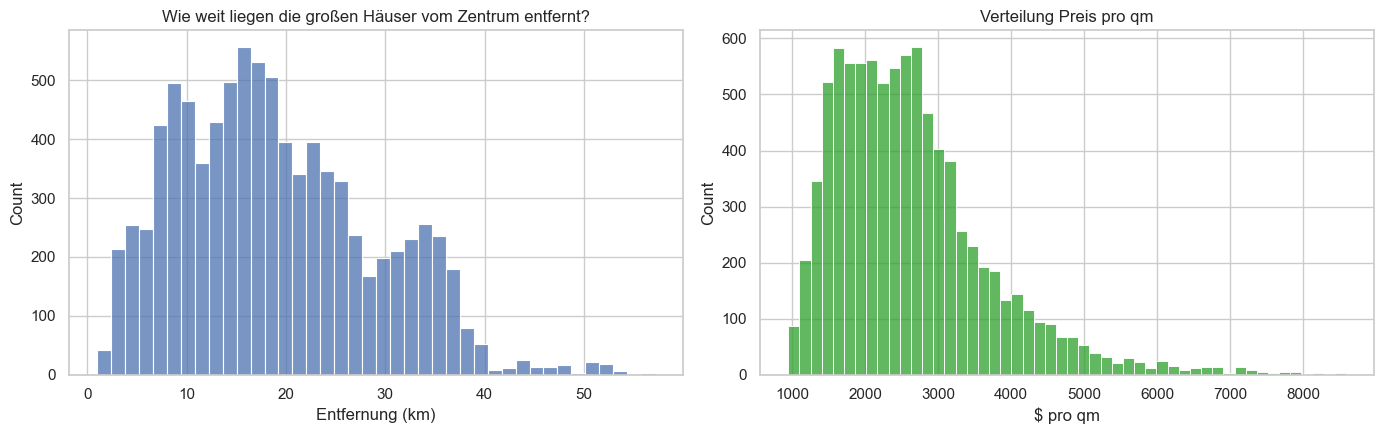

Median-Entfernung: 17.6 km | Median qm-Preis: 2,450 $


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(gross["km"], bins=40, ax=axes[0])
axes[0].set_title("Wie weit liegen die großen Häuser vom Zentrum entfernt?")
axes[0].set_xlabel("Entfernung (km)")
sns.histplot(gross["qm_preis"], bins=50, ax=axes[1], color="tab:green")
axes[1].set_title("Verteilung Preis pro qm")
axes[1].set_xlabel("$ pro qm")
plt.tight_layout()
plt.show()
print(f"Median-Entfernung: {gross['km'].median():.1f} km | Median qm-Preis: {gross['qm_preis'].median():,.0f} $")

**Was sehen wir?** Die meisten großen Häuser liegen **10 bis 30 km** vom Zentrum entfernt, direkt in der Innenstadt gibt es nur wenige. Der qm-Preis ist rechtsschief und liegt im Median bei rund 2.450 $.

---
## 5 · Zusammenhänge

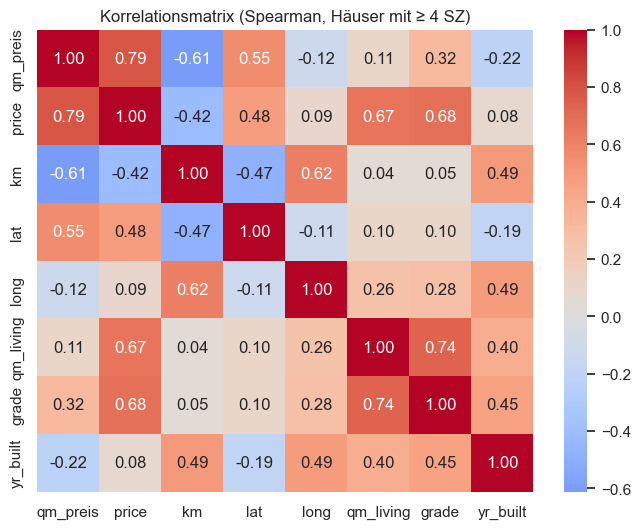

In [17]:
korr = gross[["qm_preis", "price", "km", "lat", "long", "qm_living", "grade", "yr_built"]].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korrelationsmatrix (Spearman, Häuser mit ≥ 4 SZ)")
plt.show()

**Was sehen wir?** Die **Entfernung** hat mit dem qm-Preis den **stärksten Zusammenhang** aller Merkmale (≈ −0,6, abgesehen vom Preis selbst), stärker als Bauqualität (`grade`) oder Größe. Auch `lat` ist deutlich positiv: **Im Norden ist es teurer als im Süden.** Das merken wir uns für die Folgefrage.

       size   median  vs. Zentrum
band                             
0–5     480 3,786.00         0.00
5–10   1423 3,423.00       -10.00
10–15  1509 2,823.00       -25.00
15–20  1820 2,422.00       -36.00
20–25  1291 2,383.00       -37.00
25–30   836 2,022.00       -47.00
> 30   1457 1,652.00       -56.00


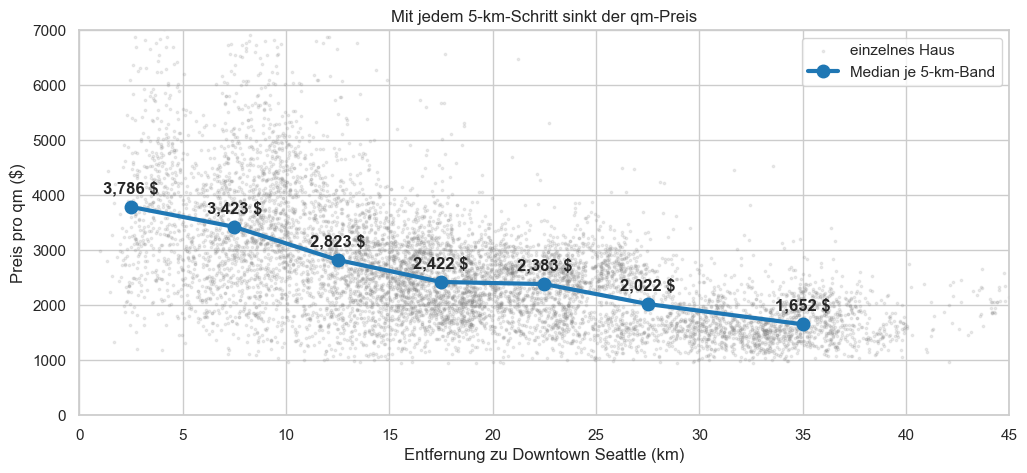

In [18]:
baender = gross.groupby("band", observed=True)["qm_preis"].agg(["size", "median"])
baender["vs. Zentrum"] = 100 * (baender["median"] / baender["median"].iloc[0] - 1)
print(baender.round(0))

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(gross["km"], gross["qm_preis"], s=3, alpha=0.15, color="gray", label="einzelnes Haus")
mitte = [2.5, 7.5, 12.5, 17.5, 22.5, 27.5, 35]
ax.plot(mitte, baender["median"], marker="o", lw=3, ms=9, color="tab:blue", label="Median je 5-km-Band")
for x, y in zip(mitte, baender["median"]):
    ax.annotate(f"{y:,.0f} $", (x, y), xytext=(0, 10), textcoords="offset points", ha="center", weight="bold")
ax.set_xlim(0, 45)
ax.set_ylim(0, 7000)
ax.set_xlabel("Entfernung zu Downtown Seattle (km)")
ax.set_ylabel("Preis pro qm ($)")
ax.set_title("Mit jedem 5-km-Schritt sinkt der qm-Preis")
ax.legend()
plt.show()

**Was sehen wir?** Von **~3.800 $/qm** im Zentrum fällt der Median-qm-Preis Schritt für Schritt auf **~1.650 $/qm** jenseits von 30 km, also um **mehr als die Hälfte**. Die Punktwolke streut aber stark: Die Entfernung erklärt viel, aber nicht alles.

---
## 6 · Hypothese prüfen
* **Spearman-Rangkorrelation:** Passt die Rangfolge „weiter weg“ zur Rangfolge „günstiger“? (−1 = perfekt gegenläufig, 0 = kein Zusammenhang)
* **Faustregel pro km:** Wir legen eine Gerade durch log(qm-Preis) und übersetzen die Steigung in „% pro km“.

In [19]:
rho, p_wert = stats.spearmanr(gross["km"], gross["qm_preis"], alternative="less")
steigung = np.polyfit(gross["km"], np.log(gross["qm_preis"]), 1)[0]
pro_km = 100 * (np.exp(steigung) - 1)

print(f"Spearman ρ = {rho:.2f}  (p = {p_wert:.1e})")
print(f"→ {'mindestens mittelstarker' if rho <= -0.3 else 'zu schwacher'} negativer Zusammenhang")
print(f"Faustregel: {pro_km:.1f} % pro km, also ca. {100 * (np.exp(steigung * 10) - 1):.0f} % pro 10 km")

# Gilt das auch für kleine Häuser? (Vergleich)
rho_klein, _ = stats.spearmanr(df.loc[df["bedrooms"] <= 3, "km"], df.loc[df["bedrooms"] <= 3, "qm_preis"])
print(f"Vergleich kleine Häuser (≤ 3 SZ): ρ = {rho_klein:.2f}")

Spearman ρ = -0.61  (p = 0.0e+00)
→ mindestens mittelstarker negativer Zusammenhang
Faustregel: -2.3 % pro km, also ca. -21 % pro 10 km
Vergleich kleine Häuser (≤ 3 SZ): ρ = -0.63


**Ergebnis:**
* ρ ≈ **−0,61**: ein **starker**, hoch signifikanter negativer Zusammenhang.
* Faustregel: **gut 2 % günstiger pro km**, also rund **ein Fünftel pro 10 km**.
* Kleine Häuser zeigen dasselbe Muster. Es ist also ein allgemeiner Lageeffekt und kein Sonderfall großer Häuser.
* **→ H2 ist bestätigt.**

---
## 7 · Folgefragen
### 7.1 Spielt die Himmelsrichtung eine Rolle?
Die Korrelationsmatrix hat gezeigt: Im Süden ist es günstiger. Wir teilen King County grob in drei Regionen:
* **Seattle & Norden:** westlich des Lake Washington, nördlich von 47,52°
* **Eastside:** östlich von 122,24° W und nördlich von 47,52° (Bellevue, Kirkland, Redmond …)
* **Süden:** südlich von 47,52° (Renton, Kent, Federal Way, Auburn …)

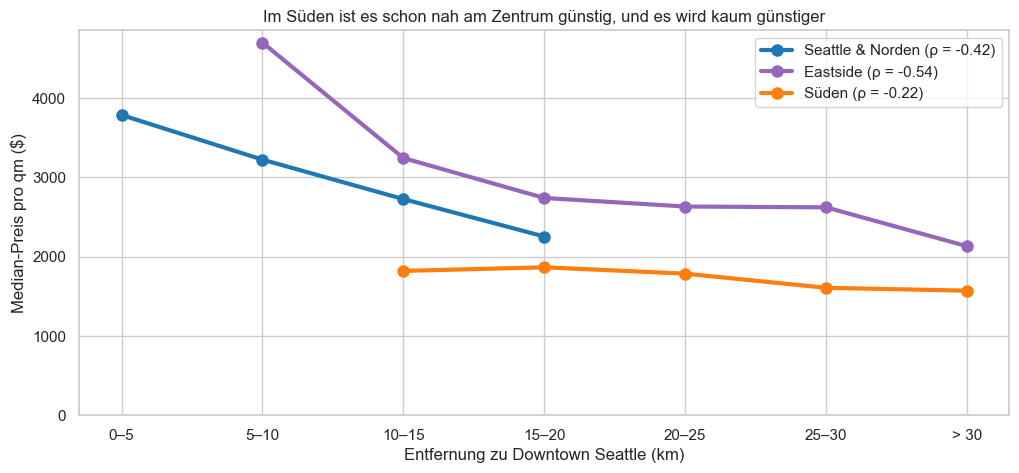

In [20]:
gross["region"] = np.select(
    [(gross["long"] >= -122.24) & (gross["lat"] >= 47.52), gross["lat"] < 47.52],
    ["Eastside", "Süden"], default="Seattle & Norden")

tab = gross.pivot_table(index="band", columns="region", values="qm_preis", aggfunc="median", observed=True)
anzahl = gross.pivot_table(index="band", columns="region", values="qm_preis", aggfunc="size", observed=True)
tab = tab.where(anzahl >= 30)  # nur Felder mit genug Häusern

fig, ax = plt.subplots(figsize=(12, 5))
farben = {"Seattle & Norden": "tab:blue", "Eastside": "tab:purple", "Süden": "tab:orange"}
for region, farbe in farben.items():
    r, _ = stats.spearmanr(gross.loc[gross["region"] == region, "km"], gross.loc[gross["region"] == region, "qm_preis"])
    ax.plot(tab.index.astype(str), tab[region], marker="o", lw=3, ms=8, color=farbe, label=f"{region} (ρ = {r:.2f})")
ax.set_xlabel("Entfernung zu Downtown Seattle (km)")
ax.set_ylabel("Median-Preis pro qm ($)")
ax.set_ylim(0)
ax.set_title("Im Süden ist es schon nah am Zentrum günstig, und es wird kaum günstiger")
ax.legend()
plt.show()

**Was sehen wir?** Bei **gleicher Entfernung** (z. B. 10–20 km) kostet der qm im **Süden ~1.850 $**, im Norden und auf der Eastside **~2.250–3.250 $**. Im Norden und Osten wirkt die Entfernung stark, **im Süden nur schwach** (ρ ≈ −0,2). Die **Richtung ist also fast so wichtig wie die Entfernung**.

### 7.2 Was bekommt Thomas für 600.000 $?

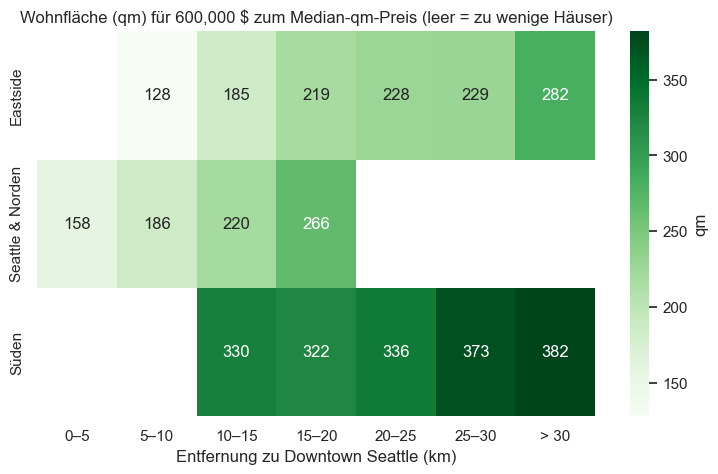

Zum Vergleich: Ein typisches großes Haus hat 233 qm.


In [21]:
BUDGET = 600_000
flaeche = (BUDGET / tab).round(0)

plt.figure(figsize=(9, 5))
sns.heatmap(flaeche.T, annot=True, fmt=".0f", cmap="Greens", cbar_kws={"label": "qm"})
plt.title(f"Wohnfläche (qm) für {BUDGET:,.0f} $ zum Median-qm-Preis (leer = zu wenige Häuser)")
plt.grid(False)
plt.xlabel("Entfernung zu Downtown Seattle (km)")
plt.ylabel("")
plt.show()
print(f"Zum Vergleich: Ein typisches großes Haus hat {gross['qm_living'].median():.0f} qm.")

**Was sehen wir?** Im Zentrum reichen 600.000 $ nur für **~160 qm**, im **Süden ab 10 km** dagegen für **über 300 qm**. Auf der Eastside erreicht man selbst jenseits von 30 km dieses Niveau nicht.

---
## 8 · Fancy Visual: interaktive Karte
Jeder Punkt ist ein großes Haus, die Farbe zeigt den Preis pro qm. Mit der Maus sieht man Details, mit dem Mausrad kann man zoomen (auch als HTML in `output/`).

In [22]:
karte = px.scatter_map(
    gross, lat="lat", lon="long", color="qm_preis",
    color_continuous_scale="Viridis", range_color=gross["qm_preis"].quantile([0.02, 0.98]).tolist(),
    hover_data={"price": ":,.0f", "qm_living": ":.0f", "km": ":.1f", "region": True, "lat": False, "long": False},
    labels={"qm_preis": "$ pro qm", "price": "Preis ($)", "qm_living": "Wohnfläche (qm)", "km": "Entfernung (km)"},
    zoom=8.8, center={"lat": 47.48, "lon": -122.18}, height=700, opacity=0.7,
    title="Große Häuser in King County: gelb = teuer pro qm, lila = günstig",
)
# Entfernungsringe um das Zentrum
winkel = np.linspace(0, 2 * np.pi, 120)
for r in [10, 20, 30]:
    karte.add_trace(go.Scattermap(
        lat=ZENTRUM_LAT + r / 111.32 * np.sin(winkel),
        lon=ZENTRUM_LON + r / (111.32 * np.cos(np.radians(ZENTRUM_LAT))) * np.cos(winkel),
        mode="lines", line=dict(color="black", width=1), name=f"{r} km", hoverinfo="name", showlegend=False))
karte.add_trace(go.Scattermap(lat=[ZENTRUM_LAT], lon=[ZENTRUM_LON], mode="markers+text", text=["Downtown"],
                              textposition="top right", marker=dict(size=14, color="red"), showlegend=False))
karte.update_layout(map_style="carto-positron", margin=dict(l=0, r=0, t=50, b=0))
karte.write_html("output/h2_easy_karte.html")
karte.show()

**Was sehen wir?** Die teuren Quadratmeter (gelb) ballen sich um Downtown und östlich des Lake Washington. Nach außen wird es dunkler, also günstiger. Der **ganze Süden** ist schon ab dem 10-km-Ring lila.

---
## 9 · Erkenntnisse & Empfehlungen

### Ergebnis
| | |
|---|---|
| Hypothese | Je weiter vom Zentrum, desto niedriger der qm-Preis (≥ 4 SZ) |
| Spearman ρ | **−0,61** (stark, p < 0,001) |
| Faustregel | **≈ −2 % pro km** |
| Zentrum vs. > 30 km | **~3.800 $ → ~1.650 $** pro qm |
| **Urteil** | **✓ H2 bestätigt** |

### Erkenntnisse
1. **Weiter raus ist deutlich günstiger:** pro km gut 2 % weniger pro qm, über 30 km hinaus mehr als die Hälfte.
2. **Die Entfernung ist der stärkste Einzelfaktor** für den qm-Preis, stärker als Bauqualität oder Hausgröße (Korrelationsmatrix).
3. **Die Richtung zählt mit (geografische Erkenntnis):** Im Süden ist es schon nah am Zentrum günstig, auf der Eastside bleibt es auch weit draußen teuer.

### Empfehlungen für Thomas
1. **Im Süden suchen** (Renton, Kent, Federal Way, Auburn), ab ca. 10 km Entfernung: Für 600.000 $ gibt es dort meist über 300 qm.
2. **Nicht unnötig weit rausziehen:** Im Süden bringt mehr Entfernung kaum noch Ersparnis, nur längere Wege für 5 Kinder.
3. **Eastside und Innenstadt meiden:** Dort ist der qm selbst 20–30 km draußen teurer als im Süden bei 10 km.

### Grenzen
Luftlinie statt Fahrzeit · Regionen grob abgegrenzt · Schulen und Nachbarschaftsqualität sind nicht im Datensatz · Markt 2014/15.